# Tendências de consumo

Este notebook responde às seguintes perguntas do projeto:

4. Quais segmentos crescem enquanto o total cai?
5. A importação de malte e lúpulo acompanha o avanço do puro malte?
6. O emprego no setor acompanha a produção?

E investiga a importação de cerveja em 2025, que cresceu 251% em volume com o valor praticamente estável.

## Preparação

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.metricas import variacao_pct

pd.options.display.float_format = "{:,.2f}".format

PASTA_SAIDA = Path("../data/processed")
PASTA_FIGURAS = Path("../docs/figuras")

TOTAL_2025 = 15_688_083_191.69
TOTAL_2024_ORIGINAL = 15_344_065_267.36

COR_SERIE = "#2a78d6"
COR_SEGUNDA = "#eb6834"
COR_ALTA = "#2a78d6"
COR_QUEDA = "#e34948"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_2 = "#52514e"
COR_GRADE = "#e4e3df"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO_2,
    "xtick.color": COR_TEXTO_2,
    "ytick.color": COR_TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "font.size": 10,
    "axes.axisbelow": True,
})

## 1. Quais segmentos crescem enquanto o total cai?

Como os volumes de 2024 vêm da base original de declarações (antes da retificação), não comparamos volumes absolutos entre os anos. Comparamos a **participação** de cada segmento no total declarado do próprio ano, a mesma escolha feita para o puro malte na fase 2.

O volume de cerveja sem álcool de 2025 foi lido do Gráfico 18 do Anuário 2026, publicado com o rótulo "Lager" por engano (ver registro de inconsistências).

In [2]:
malte_2025 = pd.read_csv(PASTA_SAIDA / "tabela_20_puro_malte_2025.csv")
malte_2024 = pd.read_csv(PASTA_SAIDA / "puro_malte_2024.csv")
carac_2025 = pd.read_csv(PASTA_SAIDA / "tabela_22_caracteristicas_2025.csv")
carac_2024 = pd.read_csv(PASTA_SAIDA / "caracteristicas_2024.csv")

def volume_de(df, coluna, comeca_com):
    filtro = df[coluna].str.lower().str.startswith(comeca_com)
    return df.loc[filtro, "volume_litros"].iloc[0]

SEM_ALCOOL_2024 = 757_444_322.53   # Anuário 2025, texto da p. 53
SEM_ALCOOL_2025 = 199_693_125.83   # Anuário 2026, Gráfico 18 (rótulo "Lager" trocado)

segmentos = pd.DataFrame([
    {"segmento": "Puro malte", "volume_2024": volume_de(malte_2024, "categoria", "cerveja puro malte"), "volume_2025": volume_de(malte_2025, "categoria", "cerveja puro malte")},
    {"segmento": "Sem álcool", "volume_2024": SEM_ALCOOL_2024, "volume_2025": SEM_ALCOOL_2025},
    {"segmento": "Sem glúten", "volume_2024": volume_de(carac_2024, "caracteristica", "sem glúten"), "volume_2025": volume_de(carac_2025, "caracteristica", "sem glúten")},
    {"segmento": "Com fruta", "volume_2024": volume_de(carac_2024, "caracteristica", "com fruta"), "volume_2025": volume_de(carac_2025, "caracteristica", "com fruta")},
    {"segmento": "Com ervas e especiarias", "volume_2024": volume_de(carac_2024, "caracteristica", "com ervas"), "volume_2025": volume_de(carac_2025, "caracteristica", "com ervas")},
    {"segmento": "Com mel", "volume_2024": volume_de(carac_2024, "caracteristica", "com mel"), "volume_2025": volume_de(carac_2025, "caracteristica", "com mel")},
    {"segmento": "Com café", "volume_2024": volume_de(carac_2024, "caracteristica", "com café"), "volume_2025": volume_de(carac_2025, "caracteristica", "com café")},
])

segmentos["pct_total_2024"] = segmentos["volume_2024"] / TOTAL_2024_ORIGINAL * 100
segmentos["pct_total_2025"] = segmentos["volume_2025"] / TOTAL_2025 * 100
segmentos["variacao_participacao_pct"] = variacao_pct(segmentos["pct_total_2025"], segmentos["pct_total_2024"])
segmentos = segmentos.sort_values("variacao_participacao_pct", ascending=False).reset_index(drop=True)

segmentos

,segmento,volume_2024,volume_2025,pct_total_2024,pct_total_2025,variacao_participacao_pct
0,Sem glúten,"71,075,867.37","367,943,519.39",0.46,2.35,406.33
1,Puro malte,"3,785,009,947.73","4,580,310,971.90",24.67,29.20,18.36
2,Com fruta,"5,854,467.02","5,856,369.74",0.04,0.04,-2.16
3,Com mel,"3,302,588.45","1,918,963.63",0.02,0.01,-43.17
4,Com ervas e especiarias,"8,498,677.98","4,470,215.70",0.06,0.03,-48.55
5,Com café,"306,160.27","148,774.49",0.00,0.00,-52.47
6,Sem álcool,"757,444,322.53","199,693,125.83",4.94,1.27,-74.21


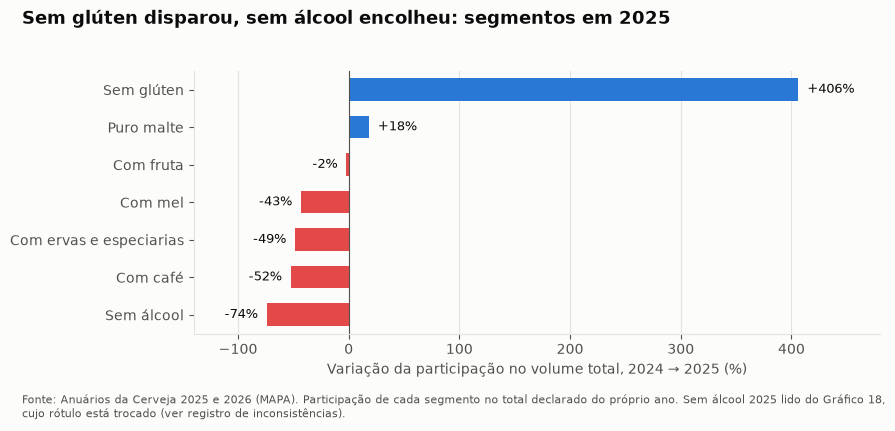

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
posicoes = range(len(segmentos))
cores = [COR_ALTA if valor > 0 else COR_QUEDA for valor in segmentos["variacao_participacao_pct"]]

ax.barh(list(posicoes), segmentos["variacao_participacao_pct"], color=cores, height=0.6)
ax.axvline(0, color=COR_TEXTO_2, linewidth=0.8)

for posicao, valor in zip(posicoes, segmentos["variacao_participacao_pct"]):
    deslocamento = 8 if valor > 0 else -8
    alinhamento = "left" if valor > 0 else "right"
    ax.text(valor + deslocamento, posicao, f"{valor:+.0f}%", va="center", ha=alinhamento, fontsize=9, color=COR_TEXTO)

ax.set_yticks(list(posicoes), segmentos["segmento"])
ax.set_ylim(len(segmentos) - 0.5, -0.5)
ax.set_xlim(-140, 480)
ax.set_xlabel("Variação da participação no volume total, 2024 → 2025 (%)")
ax.grid(axis="y", visible=False)

fig.suptitle(
    "Sem glúten disparou, sem álcool encolheu: segmentos em 2025",
    x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold",
)
fig.text(
    0.03, 0.01,
    "Fonte: Anuários da Cerveja 2025 e 2026 (MAPA). Participação de cada segmento no total declarado do próprio ano. "
    "Sem álcool 2025 lido do Gráfico 18,\ncujo rótulo está trocado (ver registro de inconsistências).",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
fig.savefig(PASTA_FIGURAS / "segmentos_2024_2025.png", dpi=150)
plt.show()

### Decomposição da variação do total

Quanto cada tipo de cerveja contribuiu para a variação do volume total? A decomposição só é possível na base original de 2024, porque o Anuário não informa como a retificação de 1,87 bilhão de litros se divide entre os tipos. Nessa base, o total **cresceu** 2,24%, e não caiu 8,85%.

In [4]:
decomposicao = malte_2024[["categoria", "volume_litros"]].merge(
    malte_2025[["categoria", "volume_litros"]],
    on="categoria",
    suffixes=("_2024", "_2025"),
)
decomposicao["contribuicao_pp"] = (
    (decomposicao["volume_litros_2025"] - decomposicao["volume_litros_2024"]) / TOTAL_2024_ORIGINAL * 100
)

print(f"Variação do total (base original): {variacao_pct(TOTAL_2025, TOTAL_2024_ORIGINAL):+.2f}%")
print(f"Soma das contribuições: {decomposicao['contribuicao_pp'].sum():+.2f} pontos percentuais")
decomposicao

Variação do total (base original): +2.24%
Soma das contribuições: +2.24 pontos percentuais


,categoria,volume_litros_2024,volume_litros_2025,contribuicao_pp
0,Cerveja Puro Malte ou 100% malte,"3,785,009,947.73","4,580,310,971.90",5.18
1,Demais cervejas,"11,559,055,319.63","11,107,772,219.79",-2.94


In [5]:
estilos_2025 = pd.read_csv(PASTA_SAIDA / "tabela_21_estilos_2025.csv")
estilos_2024 = pd.read_csv(PASTA_SAIDA / "estilos_2024.csv")
estilos_2025["chave"] = estilos_2025["estilo"].str.lower()
estilos_2024["chave"] = estilos_2024["estilo"].str.lower()

estilos = estilos_2024[["chave", "volume_litros"]].merge(
    estilos_2025[["chave", "volume_litros"]],
    on="chave",
    suffixes=("_2024", "_2025"),
)
estilos["variacao_volume_pct"] = variacao_pct(estilos["volume_litros_2025"], estilos["volume_litros_2024"])
estilos.sort_values("volume_litros_2025", ascending=False)

,chave,volume_litros_2024,volume_litros_2025,variacao_volume_pct
4,malzbier,"46,701,564.39","40,447,911.89",-13.39
3,ipa,"29,913,104.80","29,660,546.34",-0.84
8,outras ales,"8,743,739.48","16,087,778.35",83.99
5,pale ale,"2,937,193.14","12,591,354.44",328.69
6,red ale,"1,199,818.53","845,830.70",-29.50
9,outras,"1,851,435.31","753,628.19",-59.29
0,ale alemã,"269,492.80","705,357.26",161.74
1,catharina sour,"410,534.78","365,484.41",-10.97
7,saison,"202,045.28","22,945.00",-88.64
2,cerveja selvagem brasileira,"20,038.28","8,016.00",-60.00


**Resposta:** dois segmentos ganharam espaço em 2025.

- **Puro malte:** a participação subiu de 24,7% para 29,2% do volume. Na base em que a decomposição é possível, ele explica todo o crescimento do total (+5,18 pontos, contra −2,94 das demais cervejas).
- **Sem glúten:** a participação quintuplicou, de 0,46% para 2,35%, chegando a 368 milhões de litros.

A **cerveja sem álcool** foi na direção contrária: de 4,9% para 1,3% do volume, depois de ter saltado de 0,8% em 2023. Uma oscilação dessas sugere mudança na forma de declarar, e o segmento não é tratado como tendência.

As características artesanais (fruta, mel, ervas, café) somam menos de 0,1% do volume, e os estilos especiais comparáveis ficaram estáveis ou em queda (IPA −0,8%, Malzbier −13%). **O crescimento está no puro malte industrial, não no artesanal.**

## 2. A importação de malte e lúpulo acompanha o avanço do puro malte?

O puro malte usa apenas malte de cevada, sem cereais adjuntos, então um avanço do segmento deveria aumentar a demanda por malte. Parte do malte é produzida no Brasil, então a importação mede só uma parte da demanda.

Usamos as séries mensais de importação do Comex Stat (2015–2025), em peso líquido. A comparação com o puro malte só é possível em 2024 e 2025, os anos com dados de produção por tipo de cerveja.

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

insumos = pd.read_csv(
    PASTA_SAIDA / "comex_insumos_mensal_2015_2025.csv",
    parse_dates=["data"],
    dtype={"sh4": str},
)
importacao = insumos[insumos["fluxo"] == "importacao"]

serie = importacao.pivot_table(index="data", columns="sh4", values="kg_liquido", aggfunc="sum")
serie = serie.rename(columns={"1107": "malte", "1210": "lupulo"})
serie = serie.asfreq("MS", fill_value=0) / 1_000
serie["malte_mm12"] = serie["malte"].rolling(12).mean()
serie["lupulo_mm12"] = serie["lupulo"].rolling(12).mean()

print("Meses:", len(serie), "| meses com zero:", (serie[["malte", "lupulo"]] == 0).sum().to_dict())
serie.tail()

Meses: 132 | meses com zero: {'malte': 0, 'lupulo': 0}


sh4,malte,lupulo,malte_mm12,lupulo_mm12
data,,,,
2025-08-01,"68,092.86",41.67,"89,001.17",191.55
2025-09-01,"71,157.93",236.76,"86,985.93",197.80
2025-10-01,"112,212.37",121.64,"84,272.12",193.82
2025-11-01,"73,679.93",163.03,"82,457.32",200.16
2025-12-01,"144,976.32",371.79,"86,135.55",212.16


In [7]:
anual = importacao.groupby(["ano", "sh4"])[["kg_liquido", "valor_fob_usd"]].sum().unstack("sh4")
anual.columns = [f"{medida}_{'malte' if sh4 == '1107' else 'lupulo'}" for medida, sh4 in anual.columns]

anual["mil_t_malte"] = anual["kg_liquido_malte"] / 1_000_000
anual["mil_t_lupulo"] = anual["kg_liquido_lupulo"] / 1_000_000
anual["usd_kg_malte"] = anual["valor_fob_usd_malte"] / anual["kg_liquido_malte"]
anual["usd_kg_lupulo"] = anual["valor_fob_usd_lupulo"] / anual["kg_liquido_lupulo"]
anual["var_malte_pct"] = variacao_pct(anual["kg_liquido_malte"], anual["kg_liquido_malte"].shift(1))
anual["var_lupulo_pct"] = variacao_pct(anual["kg_liquido_lupulo"], anual["kg_liquido_lupulo"].shift(1))

anual[["mil_t_malte", "var_malte_pct", "usd_kg_malte", "mil_t_lupulo", "var_lupulo_pct", "usd_kg_lupulo"]]

,mil_t_malte,var_malte_pct,usd_kg_malte,mil_t_lupulo,var_lupulo_pct,usd_kg_lupulo
ano,,,,,,
2015,726.10,NaN,0.57,1.90,NaN,10.59
2016,870.58,19.90,0.55,1.72,-9.04,11.06
2017,809.16,-7.06,0.51,1.84,6.89,11.74
2018,800.67,-1.05,0.51,2.42,31.36,12.72
2019,"1,091.56",36.33,0.50,2.70,11.67,14.58
2020,"1,143.90",4.80,0.47,2.11,-21.87,13.61
2021,"1,427.42",24.79,0.49,3.51,66.00,14.05
2022,"1,282.46",-10.16,0.58,2.80,-20.12,12.31
2023,"1,300.69",1.42,0.67,2.07,-26.04,13.82


In [8]:
PURO_MALTE = pd.Series({
    2023: 3_785_009_947.73 / (1 - 0.155),   # derivado: 2024 caiu 15,5% (Anuário 2025, Tabela 20)
    2024: 3_785_009_947.73,                 # Anuário 2025, Tabela 20
    2025: 4_580_310_971.90,                 # Anuário 2026, Tabela 20
})

comparacao_malte = pd.DataFrame({
    "puro_malte_var_pct": variacao_pct(PURO_MALTE, PURO_MALTE.shift(1)),
    "malte_importado_var_pct": anual["var_malte_pct"],
    "lupulo_importado_var_pct": anual["var_lupulo_pct"],
}).loc[[2024, 2025]]

comparacao_malte

,puro_malte_var_pct,malte_importado_var_pct,lupulo_importado_var_pct
2024,-15.50,-9.18,18.27
2025,21.01,-12.50,3.91


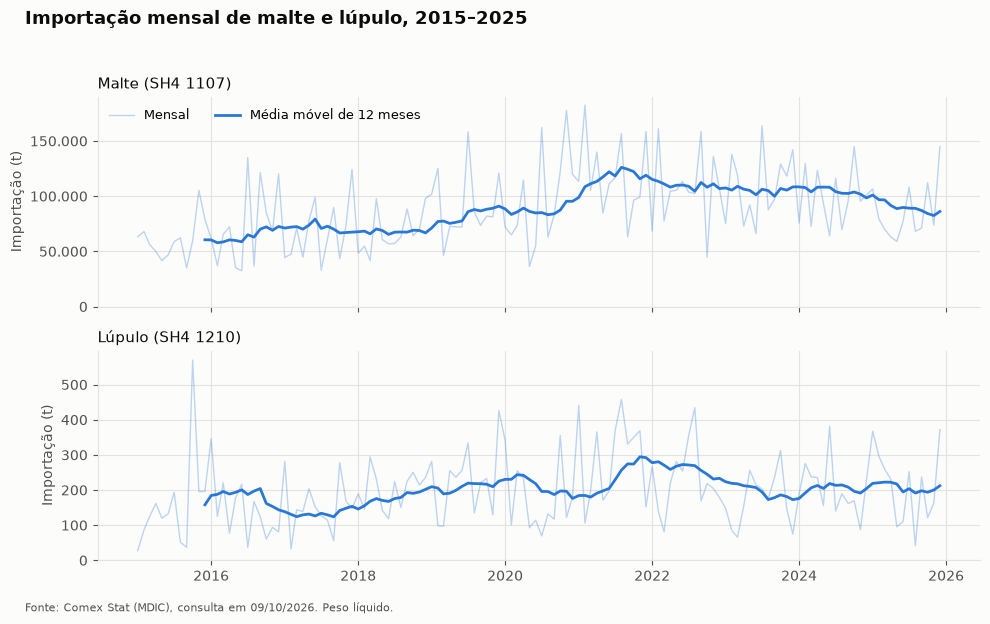

In [9]:
fig, (ax_malte, ax_lupulo) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)

for ax, coluna, titulo in [
    (ax_malte, "malte", "Malte (SH4 1107)"),
    (ax_lupulo, "lupulo", "Lúpulo (SH4 1210)"),
]:
    ax.plot(serie.index, serie[coluna], color=COR_SERIE, alpha=0.3, linewidth=1, label="Mensal")
    ax.plot(serie.index, serie[f"{coluna}_mm12"], color=COR_SERIE, linewidth=2, label="Média móvel de 12 meses")
    ax.set_title(titulo, loc="left", color=COR_TEXTO, fontsize=11)
    ax.set_ylabel("Importação (t)")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))

ax_malte.legend(loc="upper left", frameon=False, fontsize=9, ncol=2)
fig.suptitle(
    "Importação mensal de malte e lúpulo, 2015–2025",
    x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold",
)
fig.text(0.03, 0.01, "Fonte: Comex Stat (MDIC), consulta em 09/10/2026. Peso líquido.", fontsize=8, color=COR_TEXTO_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(PASTA_FIGURAS / "malte_lupulo_mensal.png", dpi=150)
plt.show()

### Sazonalidade da importação de malte

A decomposição sazonal separa a série em três partes: tendência, padrão que se repete todo ano e resto. Usamos o modelo multiplicativo, em que o efeito sazonal é uma porcentagem da tendência.

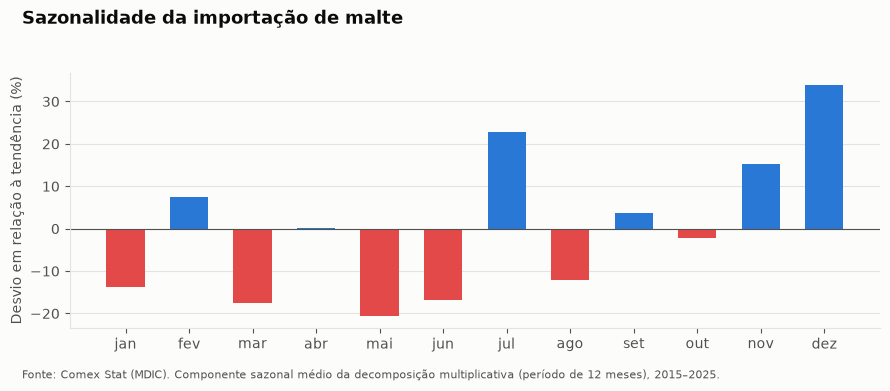

data
1    -13.70
2      7.50
3    -17.50
4      0.10
5    -20.70
6    -16.80
7     22.80
8    -12.20
9      3.60
10    -2.30
11    15.20
12    33.90
Name: seasonal, dtype: float64

In [10]:
decomposicao = seasonal_decompose(serie["malte"], model="multiplicative", period=12)
indice_sazonal = (decomposicao.seasonal.groupby(decomposicao.seasonal.index.month).mean() - 1) * 100

MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(figsize=(9, 3.8))
cores = [COR_ALTA if valor > 0 else COR_QUEDA for valor in indice_sazonal]
ax.bar(MESES, indice_sazonal, color=cores, width=0.6)
ax.axhline(0, color=COR_TEXTO_2, linewidth=0.8)
ax.set_ylabel("Desvio em relação à tendência (%)")
ax.grid(axis="x", visible=False)

fig.suptitle("Sazonalidade da importação de malte", x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold")
fig.text(
    0.03, 0.01,
    "Fonte: Comex Stat (MDIC). Componente sazonal médio da decomposição multiplicativa (período de 12 meses), 2015–2025.",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.94))
fig.savefig(PASTA_FIGURAS / "malte_sazonalidade.png", dpi=150)
plt.show()

indice_sazonal.round(1)

In [11]:
razao_tendencia = (serie["malte"] / decomposicao.trend).dropna()
consistencia = (razao_tendencia > 1).groupby(razao_tendencia.index.month).mean() * 100

pd.DataFrame({
    "desvio_medio_pct": indice_sazonal.round(1),
    "anos_acima_da_tendencia_pct": consistencia.round(0),
}).set_axis(MESES)

,desvio_medio_pct,anos_acima_da_tendencia_pct
jan,-13.70,20.00
fev,7.50,50.00
mar,-17.50,10.00
abr,0.10,50.00
mai,-20.70,10.00
jun,-16.80,20.00
jul,22.80,50.00
ago,-12.20,20.00
set,3.60,40.00
out,-2.30,50.00


**Resposta:** não. A importação de malte não acompanhou o avanço do puro malte.

- Em 2024, os dois caíram juntos (puro malte −15,5%, malte importado −9,2%). Em 2025, foram em direções opostas: o puro malte cresceu em qualquer cenário da retificação, e a importação de malte **caiu 12,5%**, para 1,03 milhão de toneladas, o menor volume desde 2018.
- A importação de malte segue um ciclo próprio: quase dobrou entre 2015 e 2021 e cai desde então. O preço médio subiu até US$ 0,67/kg em 2023 e recuou para US$ 0,54/kg em 2025.
- O lúpulo tem trajetória diferente: depois do pico de 2021 e da queda até 2023, cresceu 18% em 2024 e 4% em 2025, com preço estável.

Parte do malte usado no Brasil é produzida no país, e os dados do projeto não permitem separar o malte usado no puro malte do usado nas demais cervejas. Explicações possíveis para a divergência, como mais produção nacional de malte ou uso de estoques, não podem ser testadas aqui. Com apenas dois anos de comparação, este resultado é um indício, não uma relação estatística.

**Sazonalidade:** o único pico confiável da importação de malte é **dezembro**, 34% acima da tendência em média e acima dela em 9 de 10 anos. Março e maio são os vales mais consistentes (abaixo da tendência em 9 de 10 anos). O pico de julho (+23% em média) não se repete (5 de 10 anos) e reflete embarques grandes isolados.

## 3. O emprego no setor acompanha a produção?

O Novo CAGED informa admissões e desligamentos (fluxo), não o número de empregados (estoque). Reconstruímos o estoque mensal a partir do estoque de dezembro de 2025 da Tabela 16 do Anuário 2026, subtraindo os saldos mensais de trás para frente.

A produção anual só está disponível para 2023 a 2025, e 2024 tem dois valores (base original e retificada). Com três anos, não há base para calcular correlação: comparamos as variações e mostramos as duas séries em um índice comum (média de 2023 = 100).

In [12]:
TOTAL_2024_RETIFICADO = 17_210_754_610.75
TOTAL_2023 = 15_361_344_122.77   # Anuário 2025, texto da p. 49

caged = pd.read_csv(PASTA_SAIDA / "caged_cerveja_mensal_2020_2025.csv", parse_dates=["data"])
t16 = pd.read_csv(PASTA_SAIDA / "tabela_16_empregos_uf_2025.csv")
ESTOQUE_FIM_2025 = t16["estoque_empregos"].sum()

saldo_mensal = caged.groupby("data")["saldo"].sum().asfreq("MS", fill_value=0)
estoque = ESTOQUE_FIM_2025 - (saldo_mensal.sum() - saldo_mensal.cumsum())

estoque_dezembro = estoque[estoque.index.month == 12]
estoque_dezembro.index = estoque_dezembro.index.year
print("Estoque em dezembro de cada ano:")
display(estoque_dezembro)

ESTOQUE_FIM_2024_ANUARIO = round(0.7117 * 60_581)   # Anuário 2025, p. 44: cerveja = 71,17% de 60.581 empregos em bebidas alcoólicas
print(f"Dez/2024 reconstruído: {estoque_dezembro[2024]:,} | Anuário 2025: {ESTOQUE_FIM_2024_ANUARIO:,}")

Estoque em dezembro de cada ano:


data
2020    41660
2021    42558
2022    43493
2023    42599
2024    43113
2025    41976
Name: saldo, dtype: int64

Dez/2024 reconstruído: 43,113 | Anuário 2025: 43,115


In [13]:
emprego_medio = estoque.groupby(estoque.index.year).mean()

indices = pd.DataFrame({
    "emprego_medio": emprego_medio,
    "producao_original": pd.Series({2023: TOTAL_2023, 2024: TOTAL_2024_ORIGINAL, 2025: TOTAL_2025}),
    "producao_retificada": pd.Series({2023: TOTAL_2023, 2024: TOTAL_2024_RETIFICADO, 2025: TOTAL_2025}),
})
indices = indices / indices.loc[2023] * 100

display(indices.loc[2023:].round(1))
print("Variação de 2024 para 2025 (%):")
variacao_pct(indices.loc[2025], indices.loc[2024]).round(1)

,emprego_medio,producao_original,producao_retificada
2023,100.00,100.00,100.00
2024,100.10,99.90,112.00
2025,99.40,102.10,102.10


Variação de 2024 para 2025 (%):


emprego_medio         -0.70
producao_original      2.20
producao_retificada   -8.80
dtype: float64

In [14]:
uf_regiao = pd.read_csv(PASTA_SAIDA / "grafico_02_cervejarias_uf_2025.csv")[["uf", "regiao"]]
t16_regiao = t16.merge(uf_regiao, on="uf")

estoque_2025_regiao = t16_regiao.groupby("regiao")["estoque_empregos"].sum()
saldo_2025_regiao = (
    caged[caged["ano"] == 2025]
    .merge(uf_regiao, on="uf")
    .groupby("regiao")["saldo"].sum()
)

emprego_producao_regiao = pd.DataFrame({
    "producao_var_pct": pd.read_csv(PASTA_SAIDA / "tabela_17_producao_regiao_2025.csv").set_index("regiao")["variacao_pct"],
    "emprego_var_pct": variacao_pct(estoque_2025_regiao, estoque_2025_regiao - saldo_2025_regiao),
})
emprego_producao_regiao.round(1)

,producao_var_pct,emprego_var_pct
regiao,,
Centro-Oeste,-5.60,-4.20
Nordeste,-8.10,-3.60
Norte,-16.90,-3.30
Sudeste,-9.40,-1.50
Sul,-8.90,-4.90


In [15]:
producao_2025_regiao = pd.read_csv(PASTA_SAIDA / "tabela_17_producao_regiao_2025.csv").set_index("regiao")["volume_litros"]
producao_2024_original_regiao = pd.read_csv(PASTA_SAIDA / "producao_regiao_2024.csv").set_index("regiao")["volume_litros"]

emprego_producao_regiao["producao_var_base_original_pct"] = variacao_pct(producao_2025_regiao, producao_2024_original_regiao)
emprego_producao_regiao.round(1)

,producao_var_pct,emprego_var_pct,producao_var_base_original_pct
regiao,,,
Centro-Oeste,-5.60,-4.20,0.70
Nordeste,-8.10,-3.60,15.50
Norte,-16.90,-3.30,-2.60
Sudeste,-9.40,-1.50,-3.10
Sul,-8.90,-4.90,4.00


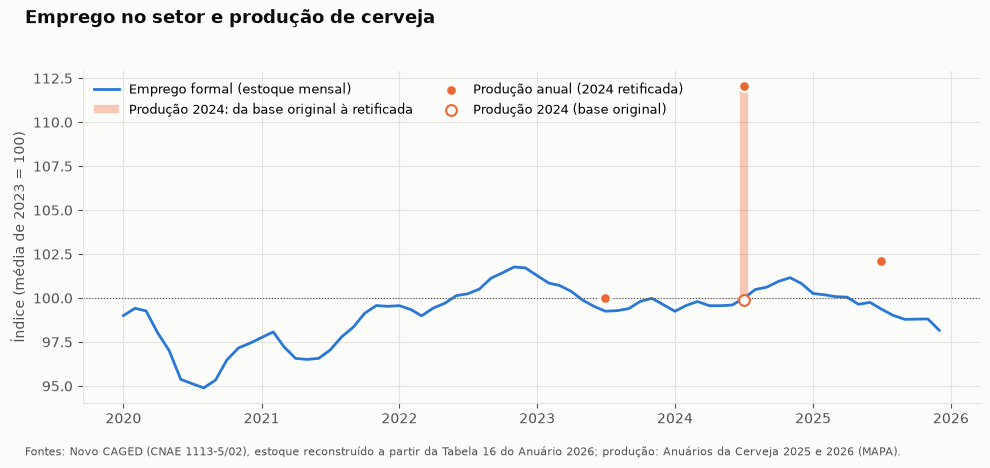

In [16]:
indice_mensal = estoque / emprego_medio[2023] * 100
meio_do_ano = pd.to_datetime([f"{ano}-07-01" for ano in [2023, 2024, 2025]])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(indice_mensal.index, indice_mensal, color=COR_SERIE, linewidth=2, label="Emprego formal (estoque mensal)")
ax.vlines(
    meio_do_ano[1], indices.loc[2024, "producao_original"], indices.loc[2024, "producao_retificada"],
    color=COR_SEGUNDA, alpha=0.35, linewidth=6, label="Produção 2024: da base original à retificada",
)
ax.scatter(
    meio_do_ano, indices.loc[2023:2025, "producao_retificada"], color=COR_SEGUNDA, s=60,
    edgecolor=COR_FUNDO, linewidth=1.5, zorder=3, label="Produção anual (2024 retificada)",
)
ax.scatter(
    [meio_do_ano[1]], [indices.loc[2024, "producao_original"]], color=COR_FUNDO, edgecolor=COR_SEGUNDA,
    linewidth=1.5, s=60, zorder=3, label="Produção 2024 (base original)",
)
ax.axhline(100, color=COR_TEXTO_2, linewidth=0.8, linestyle=":")
ax.set_ylabel("Índice (média de 2023 = 100)")
ax.legend(loc="upper left", frameon=False, fontsize=9, ncol=2)

fig.suptitle("Emprego no setor e produção de cerveja", x=0.03, ha="left", fontsize=13, color=COR_TEXTO, fontweight="bold")
fig.text(
    0.03, 0.01,
    "Fontes: Novo CAGED (CNAE 1113-5/02), estoque reconstruído a partir da Tabela 16 do Anuário 2026; "
    "produção: Anuários da Cerveja 2025 e 2026 (MAPA).",
    fontsize=8, color=COR_TEXTO_2,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(PASTA_FIGURAS / "emprego_producao.png", dpi=150)
plt.show()

**Resposta:** não é possível afirmar que o emprego acompanha a produção.

- **O emprego tem trajetória própria.** Depois da queda de cerca de 5% em meados de 2020, recuperou-se até o pico de dezembro de 2022 (43.493 empregos), ficou estável em 2023 e 2024 e **caiu ao longo de 2025**: −1.137 empregos de dezembro a dezembro (−2,6%), o menor nível desde 2020. A queda ocorreu nas cinco regiões.
- **A produção de 2025 tem direção incerta.** Em relação a 2024, ela caiu 8,8% na base retificada e cresceu 2,2% na original. O emprego médio do ano (−0,7%) fica entre as duas.
- **Nas regiões, não há relação de tamanho** entre as variações de emprego e de produção, em nenhuma das duas bases. O Nordeste, por exemplo, cresceu 15,5% em produção na base original e perdeu 3,6% dos empregos.

Com três anos de produção, não há dados para medir correlação. A reconstrução do estoque de empregos foi validada com o Anuário 2025: 43.113 empregos em dezembro de 2024, contra 43.115 informados na publicação.

## 4. Investigação: a importação de cerveja em 2025

O Anuário 2026 informa que a importação de cerveja cresceu 251% em volume em 2025 e apenas 1,7% em valor, com os EUA a 0,01 US$/L. O Comex Stat confirma o volume (seção 3 do notebook 02).

Para localizar a origem, comparamos a quantidade em litros com o peso em quilos de cada mês. Cerveja tem densidade próxima de 1 kg/L, então a razão litros/kg deve ficar perto de 1. Um registro muito fora disso indica erro na quantidade declarada.

In [17]:
cerveja_comex = pd.read_csv(PASTA_SAIDA / "comex_cerveja_mensal_2015_2025.csv", parse_dates=["data"], dtype={"ncm": str})
importacao_cerveja = cerveja_comex[cerveja_comex["fluxo"] == "importacao"].copy()

importacao_cerveja["litros_por_kg"] = importacao_cerveja["litros"] / importacao_cerveja["kg_liquido"]
importacao_cerveja["usd_por_litro"] = importacao_cerveja["valor_fob_usd"] / importacao_cerveja["litros"]

colunas = ["data", "ncm", "valor_fob_usd", "kg_liquido", "litros", "litros_por_kg", "usd_por_litro"]
importacao_cerveja.sort_values("litros_por_kg", ascending=False)[colunas].head(5)

,data,ncm,valor_fob_usd,kg_liquido,litros,litros_por_kg,usd_por_litro
343,2025-12-01,22029100,27122,23092,19401804,840.20,0.00
342,2025-11-01,22029100,107159,99118,160941,1.62,0.67
390,2018-11-01,22030000,6063709,7554559,9184018,1.22,0.66
242,2017-06-01,22029100,31940,48880,48880,1.00,0.65
247,2017-11-01,22029100,85621,130737,130737,1.00,0.65


In [18]:
LIMITE_LITROS_POR_KG = (0.5, 2.0)

suspeito = ~importacao_cerveja["litros_por_kg"].between(*LIMITE_LITROS_POR_KG)
print("Registros fora da faixa:", suspeito.sum())
display(importacao_cerveja.loc[suspeito, colunas])

importacao_cerveja["litros_corrigido"] = importacao_cerveja["litros"]
importacao_cerveja.loc[suspeito, "litros_corrigido"] = importacao_cerveja.loc[suspeito, "kg_liquido"]

importacao_anual = importacao_cerveja.groupby("ano")[["valor_fob_usd", "litros", "litros_corrigido"]].sum()
importacao_anual["usd_por_litro"] = importacao_anual["valor_fob_usd"] / importacao_anual["litros"]
importacao_anual["usd_por_litro_corrigido"] = importacao_anual["valor_fob_usd"] / importacao_anual["litros_corrigido"]
importacao_anual["var_litros_corrigido_pct"] = variacao_pct(importacao_anual["litros_corrigido"], importacao_anual["litros_corrigido"].shift(1))

importacao_anual.loc[2020:]

Registros fora da faixa: 7


,data,ncm,valor_fob_usd,kg_liquido,litros,litros_por_kg,usd_por_litro
253,2018-05-01,22029100,45600,61899,14666,0.24,3.11
330,2024-11-01,22029100,77967,106484,31428,0.30,2.48
332,2025-01-01,22029100,46794,70587,15737,0.22,2.97
333,2025-02-01,22029100,145703,229072,29172,0.13,4.99
334,2025-03-01,22029100,92069,137218,23669,0.17,3.89
336,2025-05-01,22029100,164027,228402,44088,0.19,3.72
343,2025-12-01,22029100,27122,23092,19401804,840.20,0.00


,valor_fob_usd,litros,litros_corrigido,usd_por_litro,usd_por_litro_corrigido,var_litros_corrigido_pct
ano,,,,,,
2020,16490072,17831245,17831245,0.92,0.92,-61.79
2021,17115154,18271361,18271361,0.94,0.94,2.47
2022,14184369,14576216,14576216,0.97,0.97,-20.22
2023,8597137,7130686,7130686,1.21,1.21,-51.08
2024,9259422,7493971,7569027,1.24,1.22,6.15
2025,9418836,26327681,7501582,0.36,1.26,-0.89


In [19]:
PASTA_BRUTOS = Path("../data/raw")

por_pais = pd.read_csv(
    PASTA_BRUTOS / "comex_cerveja_importacao_pais_2024_2025.csv",
    sep=";", encoding="utf-8-sig", dtype=str,
)
por_pais.columns = ["ano", "mes_texto", "ncm", "descricao", "pais", "valor_fob_usd", "kg_liquido"]
for coluna in por_pais.columns:
    por_pais[coluna] = por_pais[coluna].str.strip()

por_pais["ano"] = por_pais["ano"].astype(int)
por_pais["mes"] = por_pais["mes_texto"].str[:2].astype(int)
por_pais[["valor_fob_usd", "kg_liquido"]] = por_pais[["valor_fob_usd", "kg_liquido"]].astype(int)

mes_anomalo = por_pais[(por_pais["ano"] == 2025) & (por_pais["mes"] == 12) & (por_pais["ncm"] == "22029100")]
display(mes_anomalo[["pais", "valor_fob_usd", "kg_liquido"]])

eua = por_pais[por_pais["pais"] == "Estados Unidos"].groupby("ano")[["valor_fob_usd", "kg_liquido"]].sum()
eua["var_kg_pct"] = variacao_pct(eua["kg_liquido"], eua["kg_liquido"].shift(1))
eua

,pais,valor_fob_usd,kg_liquido
0,Alemanha,2234,1764
1,Estados Unidos,24888,21328


,valor_fob_usd,kg_liquido,var_kg_pct
ano,,,
2024,229651,173452,NaN
2025,276381,169162,-2.47


**Resposta:** o salto de 251% na importação de cerveja em 2025 não existiu. Ele vem de **um único registro**: cerveja sem álcool importada dos Estados Unidos em dezembro de 2025, declarada com 19,4 milhões de litros para cerca de 21 toneladas e US$ 24.888 (840 litros por quilo, US$ 0,0014 por litro). A quantidade provavelmente foi declarada em unidade errada.

- Pela regra de consistência (litros por quilo entre 0,5 e 2), 7 registros têm volume incoerente, todos de cerveja sem álcool (NCM 22029100), 5 deles entre novembro de 2024 e dezembro de 2025.
- Corrigida, a importação de 2025 fica entre 6,9 e 7,5 milhões de litros, conforme a correção: **entre −7% e −1% em relação a 2024**, e não +251%. O preço médio volta a US$ 1,26 por litro, em linha com os anos anteriores.
- Em quilos, a importação dos Estados Unidos **caiu 2,5%** em 2025. O crescimento de 13.178% publicado no Anuário existe só na quantidade declarada em litros.

O erro está na base do Comex Stat e foi reproduzido pelo Anuário 2026 nas tabelas 7 e 13.

## Conclusão 

4. **O crescimento está no puro malte industrial.** A participação do puro malte subiu de 24,7% para 29,2% do volume, e na base em que a decomposição é possível ele explica todo o crescimento do total. O sem glúten quintuplicou (0,46% para 2,35%). Características artesanais e estilos especiais ficaram estáveis ou em queda.
5. **A importação de malte não acompanhou o puro malte.** Caiu 12,5% em 2025, para o menor volume desde 2018. O único padrão sazonal confiável é o pico de dezembro.
6. **O emprego não acompanha a produção de forma mensurável.** Caiu 2,6% em 2025, nas cinco regiões, enquanto a direção da produção depende da base usada.
7. **O salto da importação de cerveja em 2025 é um erro de declaração.** Um único registro de cerveja sem álcool dos EUA explica os +251%; corrigida, a importação ficou estável ou em leve queda.